# 02 Exploring the data

Exploratory analysis of the corpus. Every cleaning rule in notebook 03 comes from a finding here.

Questions answered:
1. How are the star ratings spread? (class balance)
2. How long are the reviews? (how many can mention an aspect at all)
3. Which years were they written in? (temporal drift)
4. Is the new EcoCash app rated better than the old one over the same period?
5. How much Shona and Ndebele is there, and which non-dictionary words do people use? (cleaning rules, lexicon)

In [1]:
# Setup
import sys, warnings
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from absa.setup import ensure_resources
from absa import viz
ensure_resources()
viz.use_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

In [2]:
from absa.config import APPS, RAW_REVIEWS, stars_to_label

df = pd.read_csv(RAW_REVIEWS, parse_dates=["at"], encoding="utf-8-sig")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6208 entries, 0 to 6207
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   reviewId       6208 non-null   str           
 1   app            6208 non-null   str           
 2   brand          6208 non-null   str           
 3   split          6208 non-null   str           
 4   content        6206 non-null   str           
 5   score          6208 non-null   int64         
 6   at             6208 non-null   datetime64[us]
 7   thumbsUpCount  6208 non-null   int64         
 8   appVersion     5245 non-null   str           
dtypes: datetime64[us](1), int64(2), str(6)
memory usage: 1.1 MB


* `content` has 2 empty reviews. They are removed in cleaning (rule 1).
* `appVersion` is missing for about 960 reviews (Google does not always record it, for example for web reviews), so it
  is not used as a feature.

In [3]:
summary = (df.groupby("app")
             .agg(reviews=("reviewId", "size"),
                  mean_stars=("score", "mean"),
                  first=("at", "min"), last=("at", "max"))
             .assign(split=lambda t: t.index.map(lambda a: APPS[a]["split"]),
                     type=lambda t: t.index.map(lambda a: APPS[a]["type"]))
             .sort_values(["split", "reviews"], ascending=[False, False]))
summary["mean_stars"] = summary["mean_stars"].round(2)
summary

,reviews,mean_stars,first,last,split,type
app,,,,,,
CBZ Touch,1628,3.71,2016-04-12 21:27:10,2026-10-21 09:55:10,train,banking
InnBucks,1576,3.88,2021-08-26 20:39:02,2026-10-22 14:50:16,train,mobile money
EcoCash,795,3.15,2024-05-07 20:18:54,2026-10-22 18:19:38,train,mobile money
EcoCash Super App,1195,4.04,2026-04-23 10:02:09,2026-10-23 14:53:15,test,mobile money
CABS,402,2.98,2017-04-28 10:25:58,2026-10-21 15:22:29,test,banking
MyZB,358,2.77,2023-01-22 14:05:20,2026-10-16 12:18:49,test,banking
O'mari,180,2.97,2022-12-26 14:33:56,2026-10-21 21:06:21,test,mobile money
OneMoney,74,3.34,2024-12-22 05:58:51,2026-10-19 02:47:49,test,mobile money


## 1. Star ratings and class balance

In [4]:
stars = pd.crosstab(df["app"], df["score"], normalize="index").round(2)
stars

score,1,2,3,4,5
app,,,,,
CABS,0.38,0.08,0.08,0.09,0.36
CBZ Touch,0.21,0.04,0.08,0.16,0.51
EcoCash,0.36,0.07,0.07,0.08,0.42
EcoCash Super App,0.18,0.04,0.03,0.08,0.67
InnBucks,0.19,0.05,0.06,0.11,0.60
MyZB,0.46,0.07,0.05,0.07,0.35
O'mari,0.43,0.04,0.03,0.12,0.38
OneMoney,0.36,0.03,0.04,0.04,0.53


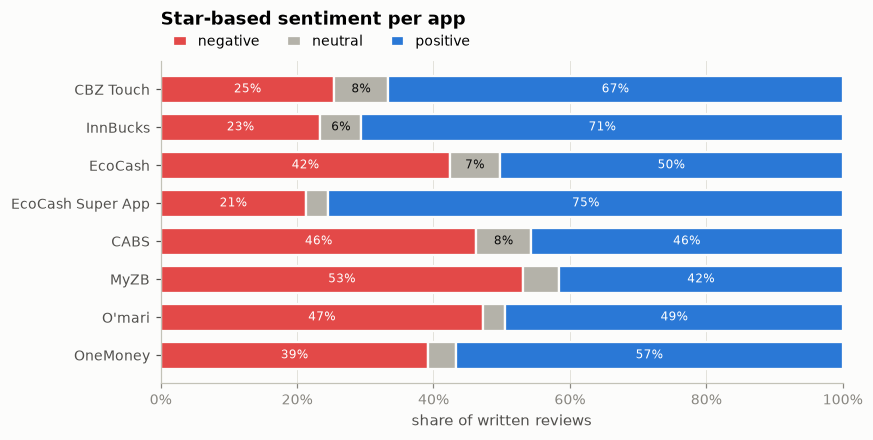

In [5]:
df["label"] = df["score"].map(stars_to_label)

shares = pd.crosstab(df["app"], df["label"], normalize="index")
order = summary.index.tolist()

fig, ax = plt.subplots(figsize=(8, 3.8))
viz.sentiment_bars(ax, shares.loc[order])
ax.set_title("Star-based sentiment per app", pad=24)
ax.set_xlabel("share of written reviews")
viz.save(fig, "02_star_sentiment_by_app")
plt.show()

Findings:
* Every app is U-shaped: people write when they are very happy (5 stars) or very angry (1 star). 3 stars is only 3 to 8%,
  so the neutral class is small (about 7% of training reviews). That is why the main score is macro-F1 and why the
  models use class weights.
* The test brands are much more negative than the training apps (MyZB 53%, O'mari 47%, CABS 46% negative, against about
  28% in training). The model learns from mostly positive reviews and is tested on mostly negative ones
  (distribution shift).
* The EcoCash Super App is the most positive app (75% positive), despite the "bring back the old app" complaints.
  Possible reasons: in-app rating prompts after a successful payment, and a referral campaign (several 5-star reviews
  are actually about referral money that was not paid).

## 2. Review length

In [6]:
df["n_words"] = df["content"].str.split().str.len()

print(df.groupby("app")["n_words"].describe()[["count", "mean", "50%", "75%", "max"]].round(1))

short = df["n_words"] <= 3
print(f"\nReviews with 3 words or fewer: {short.sum()} ({short.mean():.0%})")

                    count  mean  50%   75%    max
app                                              
CABS                402.0  13.4  7.0  17.0  109.0
CBZ Touch          1626.0  10.5  5.0  13.0  103.0
EcoCash             795.0  12.3  7.0  17.0   96.0
EcoCash Super App  1195.0   9.6  4.0  10.0  108.0
InnBucks           1576.0   8.3  3.0  10.0  109.0
MyZB                358.0  12.1  7.0  16.0  102.0
O'mari              180.0  12.6  7.0  17.2   97.0
OneMoney             74.0   9.0  4.5  12.0   65.0

Reviews with 3 words or fewer: 2575 (41%)


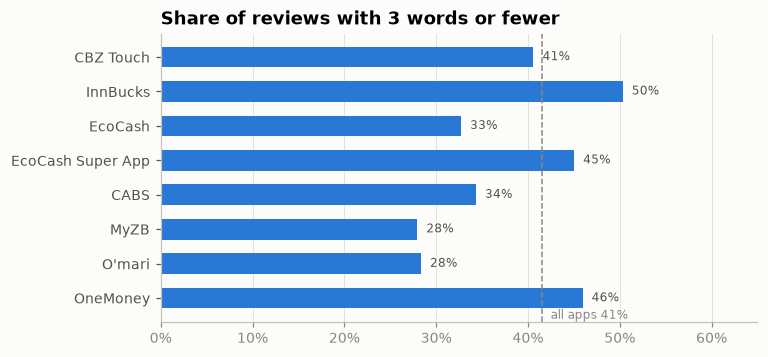

In [7]:
share_short = df.assign(short=short).groupby("app")["short"].mean().loc[order]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(share_short.index, share_short.values, color=viz.BLUE, height=0.6)
for i, v in enumerate(share_short.values):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8, color=viz.INK_2)
ax.axvline(short.mean(), color=viz.MUTED, lw=1, ls="--")
ax.text(short.mean() + 0.01, len(order) - 0.4, f"all apps {short.mean():.0%}", fontsize=8, color=viz.MUTED)
ax.invert_yaxis()
ax.set_xlim(0, 0.65)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Share of reviews with 3 words or fewer")
viz.save(fig, "02_short_reviews")
plt.show()

41% of reviews have 3 words or fewer ("good", "Great app", a thumbs-up emoji). They show how the writer feels but
almost never say about what. They are kept for training the sentiment classifier, and results are also reported
separately for short and long reviews. InnBucks and the Super App have the shortest reviews, which fits the idea of
in-app rating prompts.

## 3. When were the reviews written?

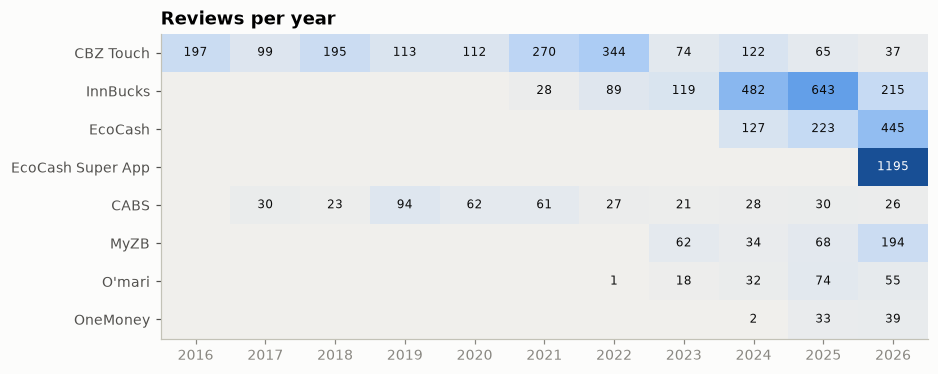

In [8]:
years = pd.crosstab(df["app"], df["at"].dt.year).loc[order]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.imshow(years.values, cmap=viz.SEQUENTIAL, aspect="auto")
ax.set_xticks(range(len(years.columns)), years.columns)
ax.set_yticks(range(len(years.index)), years.index)
for i in range(years.shape[0]):
    for j in range(years.shape[1]):
        v = years.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=8,
                    color="white" if v > years.values.max() * 0.55 else viz.INK)
ax.grid(False)
ax.set_title("Reviews per year")
viz.save(fig, "02_reviews_per_year")
plt.show()

* 82% of CBZ Touch's reviews are from before 2023, and CABS is mostly 2017 to 2021. The Super App only exists from April
  2026. The words people use and what they complain about change over time (RTGS and ZWL then, ZiG now). This is
  called temporal drift.
* Decision: the models train on all years (sentiment words hardly change, and dropping old years would cut CBZ from
  1,628 to about 300 reviews), but app comparisons only use 2024 to 2026 (`ANALYSIS_START` in `config.py`).

## 4. Old vs new EcoCash over the same six months

Window starts 2026-04-23
 app
EcoCash Super App    1195
EcoCash               167


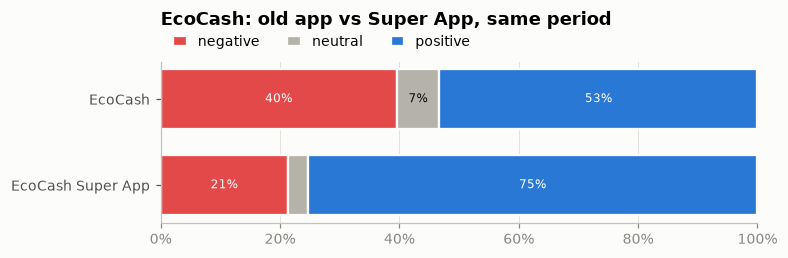

In [9]:
start = df.loc[df["app"] == "EcoCash Super App", "at"].min()

eco = df[(df["brand"] == "EcoCash") & (df["at"] >= start)]
print(f"Window starts {start:%Y-%m-%d}\n", eco["app"].value_counts().to_string())

eco_shares = pd.crosstab(eco["app"], eco["label"], normalize="index")
fig, ax = plt.subplots(figsize=(7, 1.9))
viz.sentiment_bars(ax, eco_shares)
ax.set_title("EcoCash: old app vs Super App, same period", pad=24)
viz.save(fig, "02_ecocash_same_window")
plt.show()

Over the same window the Super App is still more positive (22% vs 40% negative), so the difference is not explained by
the old app's longer history. That does not prove the new app is better: people still reviewing the old app may be the
frustrated ones (self-selection), and the old app has only 167 reviews in this window. Notebook 07 breaks the
comparison down by aspect, which is where aspect-based analysis tells us something star ratings cannot.

## 5. Local languages and non-dictionary words

In [10]:
local_words = ["mari", "hapana", "zvakanaka", "ndapota", "kutumira", "asi", "handina", "kusenda",
               "imali", "ngicela", "kuhle", "akusebenzi", "kodwa"]

pattern = r"\b(?:" + "|".join(local_words) + r")\b"

# exclude the O'mari brand name
text = df["content"].str.replace(r"\bO\s*['’]?\s*mari\b", "", case=False, regex=True)

has_local = text.str.contains(pattern, case=False, na=False)
print(f"Reviews with local-language words: {has_local.sum()} ({has_local.mean():.1%})")
df.loc[has_local, ["app", "score", "content"]].head(12)

Reviews with local-language words: 11 (0.2%)


,app,score,content
227,EcoCash,5,but pakungorova mari apo paku rikwesta
384,EcoCash,3,ine problem yekuti sometimes ukabvisa mari inoramba yakanyora old amount. Please sort it out. Generally it is a help...
515,EcoCash,2,"why can't just display our balance on menu , than kuti ndi request ku checker mari yangu mondidyira mari ku requeste..."
611,EcoCash,5,"Ndinofara zvangu ne application yenyu yamakatigadzirira iyi inoita kuona Balance yako usiri mu Zimbabwe, unokwanisa ..."
841,InnBucks,1,kubva pandango updater haichatobvume kusenda mari mazvifambisa sei ko apa pa update yenyu iyi
1138,InnBucks,1,"The app update no longer gives options for ZIPIT, Banking and Zimswitch Cards activation and settings.. It's now as ..."
1450,InnBucks,5,asi itai kut tiwane kuswiper
4231,EcoCash Super App,5,ndipei mari yangu yemaReferrals
4825,EcoCash Super App,5,Ahupihwe mari yakol kana uka share link rekuty vamwe vanhu va joiner... zvobhohwa
5019,EcoCash Super App,1,improve on requesting bank balance.Kanonyepa kaApp aka n unorara nenzara mari yakapinda kare


Only about 0.2% of reviews contain these words, far less than the proposal assumed. The English scrape got 99.7% of all
written reviews, so they are rare rather than filtered out. Mixed-language text is therefore handled as a documented
limitation, with examples, rather than a central claim. The examples do show one pattern that matters: English verbs
with Shona prefixes and endings, such as ku-send-a (to send), ku-swiper (to swipe) and va joiner. Character n-grams can
connect "kusenda" to "send"; word-level features cannot.

### Out-of-vocabulary (OOV) analysis
Which words are not in an English dictionary, ranked by how many reviews use them?

In [11]:
import re
from collections import Counter
from nltk.corpus import words

english = set(w.lower() for w in words.words())

def is_english(word):
    """Dictionary check, allowing a few common suffixes."""
    if word in english:
        return True
    return any(word.endswith(e) and word[:-len(e)] in english for e in ("s", "es", "d", "ed", "ing", "ly"))

doc_freq = Counter()
for t in df["content"].dropna():
    t = re.sub(r"\bo\s*['’]?\s*mari\b", " ", t.lower())
    tokens = set(re.findall(r"[a-z]+", t))
    doc_freq.update(w for w in tokens if len(w) >= 3 and not is_english(w))

print(f"Distinct non-dictionary words: {len(doc_freq)}")
pd.DataFrame(doc_freq.most_common(40), columns=["word", "n_reviews"]).T

Distinct non-dictionary words: 1235


,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
word,app,otp,ecocash,cbz,doesn,download,econet,airtime,innbucks,having,...,nolonger,whatsapp,samsung,zim,okay,anymore,apk,etc,logout,dstv
n_reviews,1907,199,159,139,122,70,63,59,59,49,...,18,18,17,17,17,16,16,14,13,13


Reading the top 300 by hand gave seven groups. Each one became a cleaning rule or a lexicon entry:

| Group | Examples (reviews) | Cause | Action |
|---|---|---|---|
| English words the dictionary lacks | `app` (1,907), `download`, `wifi`, `having`, `companies`, `centre` | Old word list; rough suffix rule; British spelling | Shows why proper lemmatisation exists |
| Broken contractions | `doesn` (122), `didn`, `isn`, `couldn` | `[a-z]+` splits "doesn't" at the apostrophe and loses the negation | Rule 3: expand contractions first |
| Domain terms | `otp` (199), `ussd`, `zipit`, `zesa`, `airtime`, `kyc`, `rtgs`, `zwg` | Mobile-money vocabulary | Keep them: the core of the aspect lexicon |
| Brand names and misspellings | `ecocash`, `inbucks`, `lnnbucks`, `masiyiwa`/`masiiwa` | Brands | Rule 7: standardise, then mask |
| Typos | `convinient` (22), `exellent`/`exallent`/`exerllent`, `qpp` | Typing on a phone | Rule 9: character n-grams |
| Text-speak, joined and stretched words | `pls`/`plz`/`pliz`, `nolonger`, `atleast`, `goood`, `haaaaa` | Informal writing | Rules 4 to 6: normalise |
| Shona (almost no Ndebele) | `chakadhakwa` ("it's drunk", meaning broken), `gadzirisai` (fix it), `huchi`, `bho`, `chiapp` | Mixed-language writing | Local lexicon terms |

## 6. When stars and text disagree

In [12]:
from absa.baselines import vader_compound

five = df[(df["score"] == 5) & (df["n_words"] >= 2)].copy()
five["vader"] = five["content"].map(vader_compound)
five.sort_values("vader")[["app", "score", "content", "vader"]].head(8)

,app,score,content,vader
5557,MyZB,5,This app is lekker🔥🔥🔥🔥,-0.8225
376,EcoCash,5,This application is very good but after the 24 to 25 January scheduled system upgrade it's not working perfectly as ...,-0.8154
3779,CBZ Touch,5,No need to Carry Cash anywhere and I'm not afraid of robbers or thieves anymore,-0.6705
1756,InnBucks,5,Very convenient app ...No money crisis if you wanna withdraw.. The 5 star is for enabling ZESA paying...Keep it up g...,-0.6588
3057,CBZ Touch,5,Touch is gud but your 230 is disappointing . Pliz upgrade,-0.6486
3226,CBZ Touch,5,Its failing to update why???,-0.5913
5054,EcoCash Super App,5,Amazing app 🔥🔥🔥🔥,-0.5859
1833,InnBucks,5,Very bad,-0.5849


Star ratings are a cheap but noisy label (5 stars on "poor", 5 stars on "give me my referral money"). That is why the
proposal adds a hand-labelled gold set for a fair aspect-level evaluation (notebook 06).

## Cleaning rules from this notebook

| # | Rule | Evidence |
|---|---|---|
| 1 | Remove empty reviews | `df.info()` |
| 2 | Lowercase | throughout |
| 3 | Expand contractions before splitting into words | `doesn` in 122 reviews (negation lost) |
| 4 | Normalise text-speak with a dictionary | `pls`, `nyc`, `dnt` ... |
| 5 | Split common joined words | `nolonger`, `atleast` ... |
| 6 | Shorten stretched letters | `goood`, `haaaaa` |
| 7 | Standardise, then mask, brand names | `inbucks`, `lnnbucks`; risk of shortcut learning |
| 8 | Keep domain terms | `otp` in 199 reviews, `ussd`, `zesa` |
| 9 | Leave typos to character n-grams | `convinient` in 22 reviews |
| 10 | Mask phone numbers, e-mails and links | privacy (none currently present) |
| 11 | Never treat negations or "but" as stopwords | follows from rule 3 |

A twelfth rule, an English gloss for Shona and Ndebele sentiment words, was added later after testing the interface
(see notebook 03).